# Inferring Spatio-Temporal Reaction Rates in a Fourth-Order SIR-type Model
## Physics-Informed Neural Networks with Mollifier-Based Derivative Layers

This notebook develops, end to end, a Physics-Informed Neural Network (PINN) framework
to solve an **inverse problem** for a fourth-order (bi-harmonic) reaction–diffusion
equation modeling epidemic spread with long-range dispersal. A key numerical
contribution developed here is the **mollifier layer**: a differentiable convolution
operator that replaces recursive automatic differentiation for high-order spatial
derivatives (order $k \geq 3$), which is unstable and expensive when computed by
naive nested `autograd.grad` calls.

**Contents**

1. Introduction: the inverse problem for PDEs
2. Mollifier layers: mathematical justification
3. Problem statement: a fourth-order SIR-type diffusion model
4. Numerical strategy
5. PyTorch implementation (data generation, mollifier layers, PINN, training, results)
6. Conclusions and discussion

All neural-network code uses **PyTorch** only. The notebook is self-contained and
runs end-to-end on CPU in a few minutes.


## 1. Introduction: The Inverse Problem for PDEs

### 1.1 Forward vs. inverse problems

Consider a partial differential equation written abstractly as

$$
\mathcal{N}[u](t,x;\lambda) = 0, \qquad (t,x) \in (0,T]\times\Omega,
$$

subject to initial condition $u(0,x) = u_0(x)$ and boundary conditions
$\mathcal{B}[u](t,x) = 0$ for $x\in\partial\Omega$, where $\mathcal{N}$ is a
(possibly nonlinear) differential operator that depends on a set of physical
parameters, coefficients, or source terms collectively denoted $\lambda$.

- **Forward problem.** Given $\lambda$, $u_0$, and the boundary data, find the
  solution $u(t,x)$ that satisfies the PDE. This is the classical setting of
  numerical analysis: finite differences, finite elements, spectral methods, etc.,
  are all designed to solve forward problems.

- **Inverse problem.** Given (partial, noisy) observations $u_{\text{obs}}(t_i,x_i)$
  of the solution at a finite set of space-time points $\{(t_i,x_i)\}_{i=1}^N$,
  infer the unknown parameters, coefficients, source terms, or even the operator
  $\mathcal{N}$ itself. Formally, we seek

  $$
  \lambda^\star = \arg\min_\lambda \; \mathcal{J}(\lambda) \quad \text{subject to} \quad \mathcal{N}[u](t,x;\lambda)=0 .
  $$

  The forward map $\lambda \mapsto u[\lambda]$ is generally nonlinear and only
  implicitly defined (through the PDE), which makes the inverse problem
  fundamentally harder than the forward one.

### 1.2 Ill-posedness (Hadamard's conditions)

A problem is **well-posed** in the sense of Hadamard if:

1. **Existence** — a solution exists for the given data;
2. **Uniqueness** — the solution is unique;
3. **Stability** (continuous dependence on the data) — small perturbations of the
   data produce small perturbations of the solution.

Forward problems for well-behaved PDEs (parabolic, elliptic, many hyperbolic
problems) are typically well-posed under mild assumptions on $\lambda$, $u_0$ and
$\mathcal{B}$. **Inverse problems routinely violate condition (3).** Intuitively,
recovering $\lambda$ from $u_{\text{obs}}$ requires *inverting* a smoothing
(regularizing) forward operator: diffusion, for instance, damps high-frequency
content of $\lambda$ in its effect on $u$, so the map $\lambda \mapsto u$
compresses information. Its (pseudo-)inverse therefore amplifies noise: a tiny
perturbation $\delta u_{\text{obs}}$ in the data can produce an arbitrarily large
change $\delta\lambda$ in the reconstructed parameter. This is the essence of
**ill-posedness** for inverse problems, and it is not a numerical artifact — it is
an intrinsic property of the problem.

**Regularization** restores a well-posed (or at least numerically tractable)
problem by adding prior information that penalizes undesirable reconstructions
(e.g., non-smooth, unbounded, or physically implausible $\lambda$), trading a
controlled amount of bias for a large reduction in variance.

### 1.3 Variational formulation

The inverse problem is naturally posed as a regularized least-squares
minimization:

$$
\mathcal{J}(\lambda) = \frac{1}{2}\sum_{i=1}^{N} \big| u_{\text{obs}}(t_i,x_i) - u[\lambda](t_i,x_i) \big|^2 \;+\; \mathcal{R}(\lambda),
$$

where:

- The first term is a **data-misfit** (least-squares) functional measuring the
  discrepancy between observations and the model prediction $u[\lambda]$, the
  solution of the forward PDE for a candidate parameter $\lambda$.
- $\mathcal{R}(\lambda)$ is a **regularization functional** encoding prior
  knowledge — e.g. Tikhonov regularization $\mathcal{R}(\lambda) = \alpha\|\lambda\|_{L^2}^2$,
  total variation $\mathcal{R}(\lambda)=\alpha\|\nabla\lambda\|_{L^1}$, or
  smoothness penalties $\mathcal{R}(\lambda)=\alpha\|\nabla\lambda\|_{L^2}^2$. The
  weight $\alpha>0$ trades off fidelity to data against regularity of the
  reconstruction.

Classical approaches (adjoint-state methods, Tikhonov-regularized Gauss–Newton)
solve the forward PDE explicitly (e.g. via finite differences) at every
optimization iteration and require deriving adjoint equations by hand. PINNs
offer an alternative that avoids an explicit mesh-based forward solver.

### 1.4 Physics-Informed Neural Networks (PINNs)

The central idea (Raissi, Perdikaris & Karniadakis, 2019) is to represent the
solution by a neural network $\hat u_\theta(t,x)$ with parameters $\theta$, and —
when parameters are also unknown — a second network $\hat\lambda_\phi(t,x)$ with
parameters $\phi$. Because $\hat u_\theta$ is a composition of smooth,
differentiable operations, **automatic differentiation (autodiff)** gives *exact*
derivatives $\partial_t \hat u_\theta$, $\partial_x \hat u_\theta$,
$\partial_{xx}\hat u_\theta$, ... at machine precision, evaluated at arbitrary
points $(t,x)$ — not just at grid nodes. This turns the PDE residual itself into
a differentiable quantity that can be minimized jointly with the data misfit.

Define the **PDE residual**

$$
\hat r_\theta(t,x) := \mathcal{N}\big[\hat u_\theta\big](t,x;\hat\lambda_\phi).
$$

The PINN loss combines three terms:

$$
\mathcal{L}(\theta,\phi) = \underbrace{\frac{1}{N_d}\sum_{i=1}^{N_d} \big|\hat u_\theta(t_i,x_i) - u_{\text{obs},i}\big|^2}_{\text{MSE}_{\text{data}}}
\;+\;
\underbrace{\frac{1}{N_r}\sum_{j=1}^{N_r} \big|\hat r_\theta(t_j,x_j)\big|^2}_{\text{MSE}_{\text{PDE}}}
\;+\;
\underbrace{\frac{1}{N_b}\sum_{k=1}^{N_b} \big|\mathcal{B}[\hat u_\theta](t_k,x_k)\big|^2}_{\text{MSE}_{\text{BC/IC}}} .
$$

- $\text{MSE}_{\text{data}}$ fits the network to the (sparse, noisy) observations;
- $\text{MSE}_{\text{PDE}}$ enforces the physics at a (dense) set of unlabeled
  *collocation points*, acting as a physics-based regularizer $\mathcal{R}$ in the
  variational formulation of Section 1.3;
- $\text{MSE}_{\text{BC/IC}}$ enforces known initial/boundary data exactly (in the
  least-squares sense).

Both $\theta$ and $\phi$ are trained **jointly** by minimizing $\mathcal L$ with
gradient-based optimizers, so the unknown parameter field $\hat\lambda_\phi$ is
recovered simultaneously with the state $\hat u_\theta$, without ever explicitly
solving the forward PDE on a mesh.

### 1.5 The high-order derivative problem

Autodiff computes $\partial_x^k \hat u_\theta$ by recursively differentiating the
computational graph: $\partial_x^k u = \partial_x\big(\partial_x^{k-1}u\big)$. Each
application of `torch.autograd.grad` with `create_graph=True` builds a *new*
graph on top of the previous one, so the $k$-th derivative requires traversing a
graph whose depth grows linearly with $k$ **and** whose size (number of nodes)
grows combinatorially, because differentiating a product or a $\tanh$
nonlinearity multiple times generates increasingly long expressions (this is the
well-known "expression swell" of iterated symbolic/automatic differentiation).
Concretely, for a network with $L$ layers and a smooth activation $\sigma$, each
differentiation step invokes the chain rule

$$
\partial_x \sigma(z) = \sigma'(z)\, \partial_x z ,
$$

and differentiating again requires $\sigma''(z)$, $\sigma'''(z)$, etc. For a
network of depth $L$, computing the $k$-th derivative involves — through the
generalized chain rule (Faà di Bruno's formula) — a number of terms that grows
like $O(L^k)$ (the Bell numbers count the partitions entering the multivariate
chain rule), while each term itself requires higher derivatives of the
activation, whose magnitude need not be bounded uniformly. Two concrete
consequences:

- **Error accumulation.** In floating point arithmetic, each differentiation
  stage introduces rounding error of order machine epsilon $\varepsilon_{\text{mach}}$
  relative to the *local* magnitude of the computed quantity. When two
  derivatives of similar magnitude and opposite sign are subtracted deep inside
  the graph (a form of catastrophic cancellation), the relative error can grow by
  a factor that itself scales with the derivative order, so that by $k=4$ the
  signal-to-noise ratio of $\partial_x^k\hat u_\theta$ can be severely degraded,
  especially for barely-trained (hence poorly conditioned) networks.
- **Memory scaling.** `create_graph=True` retains all intermediate activations of
  *every* previous differentiation pass so the next `backward()` can be
  differentiated as well. The memory footprint therefore grows roughly linearly
  in $k$ **times** the size of a single forward+backward pass, and for $k=4$ this
  can be 4–8$\times$ the memory (and comparable extra compute) of a first-order
  PINN, which is often the dominant cost of training on large collocation sets.

For low orders ($k\le 2$, as in classical diffusion PINNs) this cost is
acceptable. For the **bi-harmonic operator** $\Delta^2 u$ appearing in
fourth-order models (Section 3), $k=4$ nested derivatives per spatial dimension
make pure-autodiff PINNs slow and numerically fragile — motivating the
**mollifier layer** developed next, which replaces exact-but-expensive recursive
autodiff with a stable, cheap, and still differentiable convolution.


## 2. Mollifier Layers: Mathematical Justification

### 2.1 Definition of a mollifier

A **mollifier** is a smooth, compactly supported kernel used to regularize
functions by convolution. Formally, a family $\{\varphi_\epsilon\}_{\epsilon>0}$
is a mollifier if:

1. $\varphi \in C_c^\infty(\mathbb{R}^n)$ (smooth, compact support), $\varphi \geq 0$;
2. $\displaystyle\int_{\mathbb{R}^n} \varphi(x)\,dx = 1$;
3. $\varphi_\epsilon(x) = \epsilon^{-n}\varphi(x/\epsilon)$ (rescaling that
   preserves unit mass: $\int \varphi_\epsilon = \int \varphi = 1$ for every
   $\epsilon$);
4. As $\epsilon \to 0^+$, $\varphi_\epsilon \to \delta_0$ in the sense of
   distributions: for every test function $\psi$, $\int \varphi_\epsilon(x)\psi(x)\,dx \to \psi(0)$.

The canonical examples are the **Gaussian** kernel (not compactly supported,
but rapidly decaying) and the **bump function** (compactly supported), both
detailed in §2.4.

### 2.2 Approximation theorem

**Theorem (Friedrichs mollification).** Let $u \in L^p_{\text{loc}}(\mathbb{R}^n)$,
$1\le p <\infty$, and let $u_\epsilon := \varphi_\epsilon * u$. Then:

(a) $u_\epsilon \in C^\infty(\mathbb{R}^n)$ for every $\epsilon>0$ (mollification
    is always smooth, *regardless of the regularity of $u$*), because
    differentiation can be passed under the convolution integral onto the smooth
    kernel $\varphi_\epsilon$;

(b) $u_\epsilon \to u$ in $L^p_{\text{loc}}$ as $\epsilon \to 0^+$.

**Why this matters for derivatives.** Property (a) shows mollification trades
regularity: even a merely $L^p$ function becomes $C^\infty$ after convolution
with $\varphi_\epsilon$. This *legitimizes computing derivatives of $u_\epsilon$
in the classical sense* even when $u$ itself is rough (or, in our setting, when
we prefer not to trust deeply-nested autodiff derivatives of a noisy/imperfectly
trained network): we replace the (possibly numerically fragile) exact derivative
of $\hat u_\theta$ by the always-smooth, always-well-conditioned derivative of
its mollification $\hat u_{\theta,\epsilon}$, and property (b) guarantees this
approximation converges back to the true derivative as $\epsilon \to 0$
(precisely stated in §2.3).

### 2.3 Derivative approximation via convolution

A standard distributional identity: **differentiation commutes with
convolution**, in the sense that if $\varphi$ is smooth,

$$
\partial^\alpha (u * \varphi) = u * \partial^\alpha \varphi \qquad \text{for any multi-index } \alpha,
$$

which holds even when $u$ is merely a locally integrable function (or a
distribution), because all the "differentiability burden" is placed on the
smooth factor $\varphi$; no differentiability of $u$ is required. Applying this
with $\alpha = (k,0,\dots)$ (a pure $k$-th order derivative in $x$) and using
part (b) of the approximation theorem (now applied to $\partial_x^k u$, assuming
$\partial_x^k u \in L^p_{\text{loc}}$, e.g. because $u$ is a smooth network
output):

$$
\frac{\partial^k u}{\partial x^k} \;=\; \lim_{\epsilon\to0}\frac{\partial^k u}{\partial x^k}\Big( u * \varphi_\epsilon \Big)\; = \;
\lim_{\epsilon\to 0}\, u * \frac{\partial^k \varphi_\epsilon}{\partial x^k},
$$

where the last equality uses $\partial^\alpha(u*\varphi_\epsilon) = u *
\partial^\alpha \varphi_\epsilon = (\partial^\alpha u) * \varphi_\epsilon$
(convolution derivative identity applied on either factor). This justifies, for
small but finite $\epsilon$, the **approximation**

$$
\boxed{\;\frac{\partial^k u}{\partial x^k}(x) \;\approx\; \big(u * \partial_x^k \varphi_\epsilon\big)(x) \;=\; \int u(x-y)\, \partial_x^k\varphi_\epsilon(y)\, dy\;}
$$

Crucially, the right-hand side requires **no differentiation of $u$ at all** —
only pointwise evaluations of $u$ on a stencil around $x$, contracted against
the *analytically known* derivative of the kernel $\varphi_\epsilon$. This is
exactly what makes the operation cheap and stable to implement as a
**convolution layer**: $\partial_x^k \varphi_\epsilon$ is computed once, in
closed form, and reused as a fixed (non-trainable) convolution kernel for every
collocation point and every training step.

### 2.4 Choice of kernel
**Compactly supported bump function.**

$$
\varphi(x) = \begin{cases} C\exp\!\left(\dfrac{-1}{1-x^2}\right), & |x|<1,\\[4pt] 0, & |x|\ge 1,\end{cases}
\qquad C = \Big(\int_{-1}^1 e^{-1/(1-x^2)}dx\Big)^{-1},
$$

rescaled as $\varphi_\epsilon(x)=\epsilon^{-1}\varphi(x/\epsilon)$. It is exactly
zero outside $[-\epsilon,\epsilon]$ (finite stencil, no truncation error at all),
but its derivatives have no simple closed form; we obtain them once, to machine
precision, by automatic differentiation of the analytic expression itself
(cheap: this is done a single time when the kernel is built, not per training
step).

**Smoothing vs. accuracy trade-off.** The approximation error of
$u*\partial_x^k\varphi_\epsilon$ relative to $\partial_x^k u$ is, by a Taylor
expansion of $u$ inside the convolution integral, $O(\epsilon^{p})$ where $p$ is
the number of vanishing moments of $\varphi$ beyond the zeroth (for symmetric
$\varphi$, typically $O(\epsilon^2)$), **provided $u$ is resolved on a grid fine
enough that the stencil spacing $h \ll \epsilon$** (otherwise discretizing the
convolution integral by a Riemann sum introduces an additional $O(h^2/\epsilon^2)$-type
quadrature error). So:

- **Large $\epsilon$**: heavy smoothing, very stable/well-conditioned derivative
  estimate, but biased (averages away genuine small-scale variation of $u$, and
  the mollified derivative departs from the true one).
- **Small $\epsilon$**: less bias (closer to the true derivative), but the kernel
  becomes narrower and more peaked, requiring a finer evaluation stencil ($h\ll
  \epsilon$) and larger kernel derivative values ($\partial_x^k\varphi_\epsilon
  \sim \epsilon^{-k-1}$), which re-introduces sensitivity to noise in $u$ — the
  same bias/variance trade-off as in kernel density estimation or Tikhonov
  regularization, with $\epsilon$ playing the role of the regularization
  parameter.

### 2.5 Comparison with autodiff

| Aspect | Recursive autodiff ($k$-fold `grad`) | Mollifier convolution |
|---|---|---|
| How $\partial_x^k u$ is obtained | Exact, via $k$ nested reverse-mode passes through the *network's* graph | Approximate, via one convolution of network *evaluations* against an analytically known kernel derivative |
| Graph depth / memory | Grows with $k$; `create_graph=True` retains $k$ stacked graphs $\Rightarrow O(k)\times$ memory of one backward pass | $O(1)$: only a plain forward evaluation of $\hat u_\theta$ at the stencil points, plus one linear (conv) layer |
| Numerical stability | Sensitive to catastrophic cancellation in deep chain-rule expansions; error can grow with $k$ and with poor conditioning of $\theta$ | Bias–variance controlled by a single, interpretable parameter $\epsilon$; no chain-rule cancellation |
| Cost per collocation point | $O(k)$ backward passes through the whole network | One extra forward evaluation per stencil point ($2K+1$ points), fully batchable as a convolution |
| Differentiability w.r.t. $\theta$ | Yes (native) | Yes — the stencil evaluations are ordinary network outputs, so gradients still flow to $\theta$ through the (fixed-weight) convolution |
| Extra hyper-parameter | None | Mollifier width $\epsilon$ and stencil size $K$ (regularization trade-off) |
| Suitable order $k$ | Low ($k\lesssim2$) in practice | Any $k$, including $k\ge3$ (our use case: $k=4$) |

Both approaches remain differentiable with respect to the network parameters
$\theta$ (needed for training), but the mollifier route replaces *nested
autodiff* with a single extra *forward* pass and a fixed linear contraction,
which is exactly why it avoids the depth/memory/stability issues of §1.5.


## 3. Problem Statement: Inference of Diffusion and Reaction Rates in a Fourth-Order SIR Model

### 3.1 Biological motivation

Classical reaction-diffusion epidemic models (Fisher–KPP, spatial SIR) use a
second-order Laplacian $D_2\Delta u$ to model local, Brownian-like dispersal of
infected individuals. Real epidemics, however, frequently exhibit
**anomalous / long-range dispersal**: super-spreading events, long-distance
travel (air traffic, commuting), and heterogeneous contact networks all produce
fronts that move faster and are shaped differently than pure Fickian diffusion
predicts. A standard way to capture long-range, non-local-looking spread while
remaining in a *local* PDE framework is to add a **bi-harmonic** (fourth-order)
term $D_4\Delta^2 u$. Two complementary effects motivate this:

- The fourth-order term acts as a **higher-order regularizer**: it more strongly
  damps high-spatial-frequency modes than $\Delta u$ does (the symbol of
  $\Delta^2$ scales like $|k|^4$ vs. $|k|^2$ for $\Delta$), which **stabilizes**
  sharp, unphysical fronts and spurious oscillations that pure second-order
  diffusion combined with strong nonlinear reaction can otherwise produce.
- Combined with the second-order term, $D_4\Delta^2$ modifies the *dispersion
  relation* of small perturbations, changing the **characteristic front width
  and speed**: models of the Swift–Hohenberg / extended Fisher–KPP type
  ($u_t = -D_4\Delta^2 u + D_2\Delta u + f(u)$) are classical tools for
  producing traveling fronts with realistic, tunable length scales, which is
  precisely the phenomenological knob needed to fit observed epidemic front
  widths that a pure second-order model cannot reproduce.

### 3.2 The governing PDE

We consider the fourth-order reaction–diffusion ("4th-order SIR-type") equation
for the infected-fraction field $u(t,x)\in[0,1]$:

$$
u_t + D_4\, \Delta^2 u - D_2\, \Delta u = f(u;\lambda), \qquad f(u;\lambda) = \lambda(t,x)\, u\,(1-u),
$$

on $(t,x)\in(0,T]\times\Omega$, with

- $D_4 > 0$: **fourth-order (bi-harmonic) diffusion coefficient**, controlling
  long-range smoothing / stabilization of high-frequency modes;
- $D_2 \ge 0$: **second-order (classical Fickian) diffusion coefficient**,
  controlling local, short-range spreading;
- $f(u;\lambda) = \lambda(t,x)\,u(1-u)$: a **logistic reaction term** in which
  $u(1-u)$ is the classical SIR/Fisher–KPP nonlinearity (growth proportional to
  the product of "infected" and "still-susceptible" fractions, saturating at
  $u=1$), modulated by a **spatio-temporally varying effective transmission
  rate** $\lambda(t,x)$ — the unknown of interest, representing how local
  contact patterns, mobility, or interventions change the effective reproduction
  rate over space and time.

In 1D, which we use for the numerical experiments (for computational
tractability, without loss of the essential mathematical/numerical content),
$\Delta u = u_{xx}$ and $\Delta^2 u = u_{xxxx}$.

### 3.3 The inverse problem

**Given**: noisy, sparse observations
$$
u_{\text{obs}}(t_i,x_i) = u(t_i,x_i) + \eta_i, \qquad \eta_i \sim \mathcal{N}(0,\sigma^2), \qquad i=1,\dots,N,
$$
at a scattered set of space-time points $\{(t_i,x_i)\}$ (the **observation
operator** is pointwise evaluation, $\mathcal{H}[u](t_i,x_i) = u(t_i,x_i)$, i.e. a
sparse sampling of the full field, corrupted by i.i.d. additive Gaussian noise
of standard deviation $\sigma$ — a standard model for sensor/reporting noise),
together with known $D_4$, $D_2$, initial condition $u_0(x)$, and (periodic)
boundary conditions,

**find**: the spatio-temporal field $\lambda(t,x)$ (and, as a by-product, a
denoised/completed reconstruction of $u(t,x)$ everywhere in $\Omega\times(0,T]$)
that is consistent with the observations and with the governing PDE.

### 3.4 Well-posedness discussion

This is a classical **coefficient inverse problem** for a nonlinear PDE, and it
is ill-posed in Hadamard's sense: $\lambda(t,x)$ is an infinite-dimensional
unknown (a full field, not a handful of scalars) while the data
$\{u_{\text{obs},i}\}$ are finite and noisy, so uniqueness and stability fail
without further restriction (many different $\lambda$ fields can fit sparse
noisy data equally well, and the map from data to $\lambda$ is unbounded).
Wherever $u\approx0$ or $u\approx1$, the reaction term $f(u;\lambda)=\lambda
u(1-u)\to0$ **regardless of $\lambda$**, so $\lambda$ is locally unidentifiable
in those regions — a structural, not merely numerical, obstruction.

The PINN + mollifier framework regularizes the problem in two complementary
ways:

1. The **network parameterization itself acts as an implicit regularizer**: a
   moderately sized, smooth network ($\tanh$/$\sin$ activations) cannot
   represent arbitrarily rough $\lambda_\phi$, which biases the search toward
   smooth reconstructions — analogous to a Tikhonov penalty $\mathcal R(\lambda)$
   without hand-tuning $\alpha$ explicitly (though we still add an explicit
   smoothness penalty below for robustness);
2. The **PDE-residual term acts as the physics-based prior** $\mathcal
   R(\lambda)$ of the variational formulation (§1.3): it constrains $\hat
   u_\theta,\hat\lambda_\phi$ to remain consistent with the fourth-order operator
   *everywhere* in the domain (dense collocation points), not just at the sparse
   observation locations — effectively propagating information from
   well-identified regions ($u$ away from $0,1$) to poorly-identified ones.

### 3.5 Derivation of the residual

Substituting the network approximations $\hat u_\theta(t,x)\approx u(t,x)$ and
$\hat\lambda_\phi(t,x)\approx\lambda(t,x)$ into the PDE and moving every term to
one side gives the **PINN residual**:

$$
\boxed{\;\hat r(t,x) \;=\; \hat u_t \;+\; D_4\, \Delta^2 \hat u \;-\; D_2\, \Delta \hat u \;-\; \hat\lambda(t,x)\,\hat u\,(1-\hat u)\;}
$$

which the network is trained to drive to zero (in mean square) over a dense set
of collocation points. In 1D:

$$
\hat r(t,x) = \hat u_t(t,x) + D_4\, \hat u_{xxxx}(t,x) - D_2\, \hat u_{xx}(t,x) - \hat\lambda(t,x)\,\hat u(t,x)\,\big(1-\hat u(t,x)\big).
$$

Each derivative in $\hat r$ is computed differently, according to its order:

- $\hat u_t$ (order 1) and $\hat u_{xx}$ (order 2): computed by **standard
  autodiff** (`torch.autograd.grad` with `create_graph=True`), which is cheap
  and stable at these low orders (§1.5).
- $\hat u_{xxxx} = \Delta^2\hat u$ (order 4, the **bi-harmonic** term): this is
  the term that suffers from the error accumulation / memory scaling problems of
  §1.5. It is computed instead with the **mollifier convolution layer** of
  Section 2, i.e. $\hat u_{xxxx}(t,x) \approx \big(\hat u_\theta(t,\cdot) *
  \partial_x^4\varphi_\epsilon\big)(x)$, evaluated by convolving a local stencil
  of network evaluations around $x$ against the analytically-known 4th
  derivative of the mollifier kernel.


## 4. Numerical Strategy

### 4.1 Network architecture

Two fully-connected networks are used:

- $\hat u_\theta(t,x)$: input $(t,x)\in\mathbb R^2$, 4 hidden layers of width 64,
  $\tanh$ activations (smooth, infinitely differentiable — required since we
  still autodiff through it for $u_t$, $u_{xx}$, and for the stencil evaluations
  feeding the mollifier layer), output $\hat u\in\mathbb R$ passed through a
  sigmoid to softly enforce the physical range $u\in(0,1)$.
- $\hat\lambda_\phi(t,x)$: same input, 3 hidden layers of width 32, $\tanh$
  activations, linear output (no range restriction, but initialized near the
  reaction rate's expected order of magnitude via the final-layer bias).

Both use **Xavier/Glorot normal initialization**, standard for $\tanh$ networks,
to keep activations in the linear (well-conditioned) regime of $\tanh$ early in
training, which matters even more here because we differentiate $\hat u_\theta$
up to third order via autodiff for the stencil feeding the mollifier (see
below), so poorly-conditioned initial weights would corrupt those low-order
building blocks too.

### 4.2 Mollifier layer implementation plan

The mollifier layer computes $\hat u_{xxxx}(t,x)$ **without** four nested
`autograd.grad` calls. Implementation plan:

1. **Kernel.** Precompute (once, outside the training loop) the 4th derivative
   of a Gaussian mollifier $\partial_x^4\varphi_\epsilon$ on a symmetric,
   uniform stencil of offsets $\{j h\}_{j=-K}^{K}$ (closed-form via the Hermite
   polynomial $He_4$, §2.4), truncated at $M\epsilon$ so $K = \lceil M\epsilon/h\rceil$.
   This is a fixed (non-trainable) 1D tensor of length $2K+1$.
2. **Stencil evaluation.** For a batch of $N_r$ collocation points
   $\{(t_j,x_j)\}$, form the $2K+1$ shifted copies $x_j + m h$, $m=-K,\dots,K$,
   evaluate $\hat u_\theta$ at all $(t_j, x_j+mh)$ (one batched forward pass of
   size $N_r\times(2K+1)$), and reshape into a tensor of shape
   $(N_r, 1, 2K+1)$ — the "signal" for a 1D convolution, with 1 input channel.
3. **Convolution.** Apply `torch.nn.functional.conv1d` with the kernel from
   step 1 reshaped to `(out_channels=1, in_channels=1, kernel_size=2K+1)`, no
   padding ("valid" convolution: input length $2K+1$, kernel length $2K+1 \Rightarrow$
   output length $1$), stride 1. Multiplying by the stencil spacing $h$
   (Riemann-sum quadrature weight) converts the discrete sum into an
   approximation of the continuous convolution integral. The output, of shape
   $(N_r,1,1)$, is the mollified estimate of $\hat u_{xxxx}(t_j,x_j)$ for every
   $j$ in the batch — a single batched, differentiable (w.r.t. $\theta$, since
   the stencil evaluations are ordinary network outputs) linear operation.
4. **Padding / boundary handling.** Collocation points closer to the domain
   boundary than $Kh$ would need stencil points outside $\Omega$; since our
   spatial domain is **periodic**, this is resolved by evaluating the network at
   $x_j+mh$ taken **modulo the domain length** (periodic wrap-around), consistent
   with the periodic boundary condition of the forward model (§5.1) — no
   zero-padding artifacts are introduced.

### 4.3 Loss function

$$
\mathcal L(\theta,\phi) = w_d\,\text{MSE}_{\text{data}} + w_r\,\text{MSE}_{\text{PDE}} + w_{ic}\,\text{MSE}_{\text{IC}} + w_\lambda\, \mathcal R(\hat\lambda_\phi),
$$

with $\text{MSE}_{\text{data}}$, $\text{MSE}_{\text{PDE}}$ as in §1.4,
$\text{MSE}_{\text{IC}} = \frac{1}{N_{ic}}\sum |\hat u_\theta(0,x_k)-u_0(x_k)|^2$
enforcing the known initial condition (periodic BC is enforced structurally by
construction, see §5.4, so no separate boundary loss term is needed), and an
explicit smoothness regularizer

$$
\mathcal R(\hat\lambda_\phi) = \frac{1}{N_r}\sum_j \big|\partial_x \hat\lambda_\phi(t_j,x_j)\big|^2
$$

on the inferred rate field, directly instantiating $\mathcal R(\lambda)$ from
the variational formulation of §1.3 and mitigating the local
unidentifiability of $\lambda$ discussed in §3.4. The weights $(w_d,w_r,w_{ic},w_\lambda)$
are chosen so that, at initialization, all terms contribute comparably (a
standard practical heuristic for multi-term PINN losses, avoiding one term
dominating gradient descent purely due to differing scales); we use $w_d$ large
relative to $w_r$ since data are sparse and must be matched tightly, while
$w_r$ is applied over many more (unlabeled) collocation points, which already
gives the residual term a large aggregate influence.

### 4.4 Optimization

- **Optimizer**: Adam (first-order, robust to the very different curvature of
  the data/PDE/IC/regularization terms) for the bulk of training, with a
  step-decayed learning rate schedule, followed by a short **L-BFGS**
  fine-tuning phase (quasi-Newton, uses curvature information) to polish the
  solution once Adam has reached a good basin — a standard two-stage PINN
  training recipe.
- **Collocation sampling**: points are drawn once per epoch (mini-batch) via a
  combination of a **fixed space-time grid subsample** and **Latin Hypercube
  Sampling (LHS)** over $(t,x)\in[0,T]\times[0,L]$, which spreads points more
  uniformly across the 2D domain than plain uniform random sampling for the
  same sample size (lower discrepancy $\Rightarrow$ better coverage of the
  residual with fewer points).
- **Mini-batching**: given the small domain and modest network size targeted
  here, all collocation/data/IC points fit in a single batch per iteration
  (full-batch gradient descent), which keeps the training loop simple and fast.

### 4.5 Evaluation metrics

- **Relative $L^2$ error** for the state: $\displaystyle \varepsilon_u = \frac{\|\hat u_\theta - u_{\text{true}}\|_2}{\|u_{\text{true}}\|_2}$ evaluated on the full space-time reference grid.
- **Relative $L^2$ error** for the parameter: $\displaystyle \varepsilon_\lambda = \frac{\|\hat\lambda_\phi - \lambda_{\text{true}}\|_2}{\|\lambda_{\text{true}}\|_2}$.
- **Residual norm** $\|\hat r\|_2$ on a held-out set of collocation points, as a
  physics-consistency diagnostic independent of ground truth.
- **Pearson correlation** between the mollifier-estimated $\hat u_{xxxx}$ and a
  finite-difference estimate of $u_{xxxx}$ from the reference grid, to validate
  the mollifier layer's accuracy directly (isolated from the rest of the
  training pipeline).


## 5. PyTorch Implementation

### 5.1 Setup and domain

We work on a periodic 1D spatial domain $x\in[0,L)$ with $L=1$ and time
$t\in[0,T]$ with $T=1$. All physical constants are chosen so that the forward
solve is well resolved by a modest spectral grid and the network training
finishes in a couple of minutes on CPU.


In [1]:
# Core imports. PyTorch only for anything neural-network related, as required.
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.integrate import solve_ivp
from scipy.special import eval_hermitenorm  # probabilists' Hermite polynomials He_k, closed-form Gaussian derivatives
import matplotlib.pyplot as plt
import time, tracemalloc

# Reproducibility
SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)

# Force CPU by default (the notebook is designed to run end-to-end on CPU in a few
# minutes); if a GPU is available it will still work, only faster.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ---- Physical / domain parameters -----------------------------------------
L = 1.0          # spatial period
T = 1.0          # final time
D4_true = 5e-4   # fourth-order (bi-harmonic) diffusion coefficient
D2_true = 1e-2   # second-order (Fickian) diffusion coefficient

def lambda_true_fn(t, x):
    '''Ground-truth spatio-temporal reaction rate lambda(t,x) to be recovered.'''
    return 1.0 + 0.5 * np.sin(2 * np.pi * x) * np.cos(np.pi * t)

def u0_fn(x):
    '''Initial condition: a localized bump of infected fraction.'''
    return 0.05 + 0.25 * np.exp(-50.0 * (x - 0.5) ** 2)

print("Domain: x in [0, %.1f), t in [0, %.1f]" % (L, T))
print("D4_true =", D4_true, " D2_true =", D2_true)


Using device: cuda
Domain: x in [0, 1.0), t in [0, 1.0]
D4_true = 0.0005  D2_true = 0.01


### 5.2 Data generation: forward spectral solver

The forward problem is solved with a **Fourier spectral method**: on a periodic
domain, spatial derivatives of any order are obtained *exactly* (up to
round-off) by multiplying the Fourier coefficients by $(ik)^n$, avoiding any
finite-difference truncation error and making the fourth-order term trivial to
evaluate. The semi-discrete system is, however, **very stiff**: the linear part
of the right-hand side has eigenvalues $-D_4 k^4$ for every resolved
wavenumber $k$, and since $k$ reaches $O(N_x)$ on an $N_x$-point grid, the
stiffest mode decays on a timescale $\propto (D_4 N_x^4)^{-1}$ — orders of
magnitude faster than the timescale of interest. An **explicit** integrator
(e.g. RK45) must resolve that fastest mode to remain stable, forcing
prohibitively small time steps; we therefore use an **implicit, stiff-aware**
method (`method="BDF"` in `scipy.integrate.solve_ivp`), which remains stable
with much larger steps and is dramatically faster here (this is the same
stiffness phenomenon, in the *forward* problem, that motivated avoiding
recursive autodiff for the analogous 4th-order term inside the *inverse*
PINN problem in §1.5).


In [2]:
# ---- Spectral forward solver (ground truth generator) ----------------------
Nx = 64                                   # number of spatial grid points (periodic)
x_grid = np.linspace(0.0, L, Nx, endpoint=False)
dx = L / Nx
k_wave = 2 * np.pi * np.fft.fftfreq(Nx, d=dx)   # Fourier wavenumbers

def rhs(t, u):
    '''Right-hand side of u_t = -D4*u_xxxx + D2*u_xx + f(u; lambda(t,x)),
    with spatial derivatives computed spectrally (exact for periodic smooth fields).'''
    u_hat = np.fft.fft(u)
    u_xx = np.real(np.fft.ifft(-(k_wave ** 2) * u_hat))
    u_xxxx = np.real(np.fft.ifft((k_wave ** 4) * u_hat))
    lam = lambda_true_fn(t, x_grid)
    return -D4_true * u_xxxx + D2_true * u_xx + lam * u * (1.0 - u)

Nt = 101
t_grid = np.linspace(0.0, T, Nt)
u0 = u0_fn(x_grid)

sol = solve_ivp(rhs, [0.0, T], u0, t_eval=t_grid, method="BDF", rtol=1e-8, atol=1e-10)
assert sol.success, "Forward spectral solve failed"
U_true = sol.y.T   # shape (Nt, Nx): ground-truth u(t_grid[i], x_grid[j])

print("Forward solve done. U_true shape:", U_true.shape)
print("u range: [%.4f, %.4f]" % (U_true.min(), U_true.max()))


Forward solve done. U_true shape: (101, 64)
u range: [0.0382, 0.3142]


In [36]:
u = np.array([1,2,3,4], dtype= float)
np.fft.fft(u)

array([10.+0.j, -2.+2.j, -2.+0.j, -2.-2.j])

In [19]:
# ---- Sparse, noisy observations ---------------------------------------------
# Simulate realistic epidemic surveillance data: only a handful of space-time points
# are observed, and the measurement itself is corrupted by additive Gaussian noise.
N_obs = 160
sigma_noise = 0.02

rng = np.random.default_rng(SEED)
t_idx_obs = rng.integers(0, Nt, size=N_obs)
x_idx_obs = rng.integers(0, Nx, size=N_obs)

t_obs = t_grid[t_idx_obs]
x_obs = x_grid[x_idx_obs]
u_obs_clean = U_true[t_idx_obs, x_idx_obs]
u_obs = u_obs_clean + rng.normal(0.0, sigma_noise, size=N_obs)

print("Generated %d noisy observations (sigma = %.3f)" % (N_obs, sigma_noise))


Generated 160 noisy observations (sigma = 0.020)


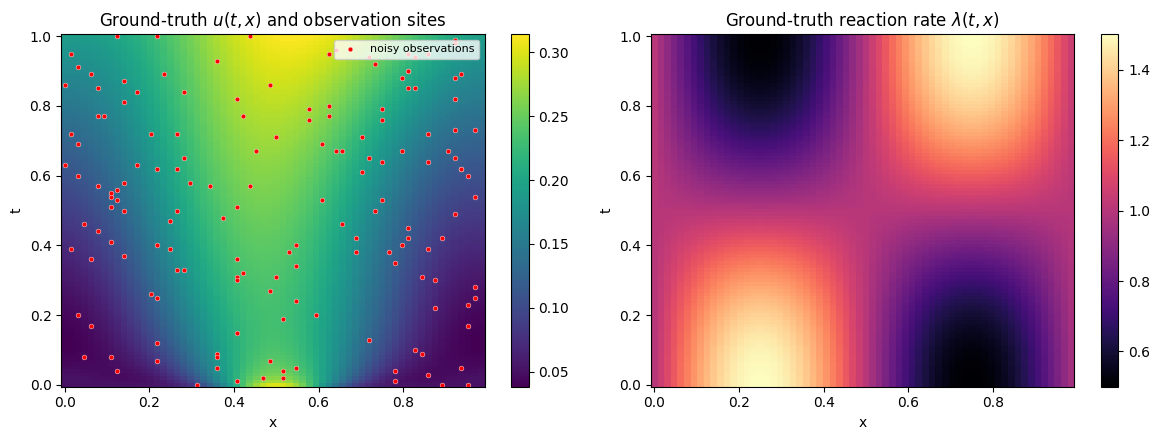

In [20]:
# ---- Visualize the ground-truth field and the observation locations ---------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

Tm, Xm = np.meshgrid(t_grid, x_grid, indexing="ij")
im0 = axes[0].pcolormesh(Xm, Tm, U_true, shading="auto", cmap="viridis")
axes[0].scatter(x_obs, t_obs, s=12, c="red", edgecolors="white", linewidths=0.3, label="noisy observations")
axes[0].set_xlabel("x"); axes[0].set_ylabel("t"); axes[0].set_title("Ground-truth $u(t,x)$ and observation sites")
axes[0].legend(loc="upper right", fontsize=8)
fig.colorbar(im0, ax=axes[0])

Lam_true_grid = lambda_true_fn(Tm, Xm)
im1 = axes[1].pcolormesh(Xm, Tm, Lam_true_grid, shading="auto", cmap="magma")
axes[1].set_xlabel("x"); axes[1].set_ylabel("t"); axes[1].set_title(r"Ground-truth reaction rate $\lambda(t,x)$")
fig.colorbar(im1, ax=axes[1])

plt.tight_layout()
plt.show()


### 5.3 Mollifier kernel utilities

We now implement the Gaussian and bump-function mollifiers and their
derivatives in closed form, in both 1D and 2D, following §2.4. Derivatives of
the Gaussian use the Hermite-polynomial formula; derivatives of the bump
function are obtained once (not per training step) via `torch.autograd` applied
directly to the analytic kernel formula, which is exact and cheap since the
kernel is a small, fixed array. 


In [21]:
# ---- 1D Gaussian mollifier and its k-th derivative (closed form) -----------
def gaussian_kernel_1d(offsets, eps, order=0):
    '''Evaluate the Gaussian mollifier phi_eps(x) (order=0) or its k-th derivative
    (order=k) at the given offsets, using the closed-form Hermite polynomial identity
        d^k/dx^k phi_eps(x) = (-1)^k / eps^k * He_k(x/eps) * phi_eps(x).
    `offsets` is a 1D numpy array of stencil positions.'''
    z = offsets / eps
    phi = np.exp(-0.5 * z ** 2) / (np.sqrt(2 * np.pi) * eps)
    if order == 0:
        return phi
    He_k = eval_hermitenorm(order, z)       # probabilists' Hermite polynomial He_k(z)
    return ((-1.0) ** order) / (eps ** order) * He_k * phi

# ---- 1D compactly supported bump-function mollifier -------------------------
def _bump_unit(x):
    '''Unnormalized bump function phi(x) = exp(-1/(1-x^2)) for |x|<1, else 0.
    Implemented with torch so we can autodiff it to get exact derivatives.'''
    out = torch.zeros_like(x)
    mask = x.abs() < 1.0
    out[mask] = torch.exp(-1.0 / (1.0 - x[mask] ** 2))
    return out

def bump_kernel_1d(offsets, eps, order=0):
    '''Evaluate the compactly-supported bump mollifier phi_eps(x) (order=0) or its
    k-th derivative (order=k) at the given offsets. The normalizing constant C is
    fixed by numerical integration of the unit bump; derivatives are obtained by
    autodiff of the analytic torch expression (exact, computed once).'''
    x = torch.tensor(offsets / eps, dtype=torch.float64, requires_grad=(order > 0))
    # Normalization constant C = 1 / integral_{-1}^{1} exp(-1/(1-x^2)) dx, via a fine quadrature grid.
    xq = torch.linspace(-0.999999, 0.999999, 200001, dtype=torch.float64)
    C = 1.0 / torch.trapz(_bump_unit(xq), xq)
    # Differentiate the unit (unnormalized) bump `order` times using autograd, then
    # rescale: phi_eps(x) = eps^-1 * C * phi_unit(x/eps)  =>  d^k/dx^k = eps^-(k+1) * C * phi_unit^(k)(x/eps).
    y = _bump_unit(x)
    for _ in range(order):
        grad_y = torch.autograd.grad(y.sum(), x, create_graph=True)[0]
        y = grad_y
    result = (C * y / (eps ** (order + 1))).detach().numpy()
    return result

print("Kernel utilities defined (1D Gaussian + 1D bump).")


Kernel utilities defined (1D Gaussian + 1D bump).


**2D generalization.** In two dimensions, the Gaussian mollifier is separable,
$\varphi_\epsilon(x,y) = \varphi_\epsilon(x)\,\varphi_\epsilon(y)$, so any mixed
partial derivative factorizes as an outer product of 1D derivative kernels:

$$
\frac{\partial^{k+l}\varphi_\epsilon}{\partial x^k\,\partial y^l}(x,y) = \Big[\frac{d^k\varphi_\epsilon}{dx^k}(x)\Big]\Big[\frac{d^l\varphi_\epsilon}{dy^l}(y)\Big],
$$

which lets us build the 2D kernel as an outer product of two 1D kernels and
apply it with `torch.nn.functional.conv2d`. This is provided below as a
general-purpose utility (used later only to validate correctness on a known
2D function; the main PINN experiment stays in 1D+time for computational
tractability, as noted in §3.2).


In [22]:
# ---- 2D Gaussian mollifier derivative (separable outer product) -------------
def gaussian_kernel_2d(offsets_x, offsets_y, eps, order_x=0, order_y=0):
    '''Build a 2D Gaussian-mollifier derivative kernel d^(ox+oy)/dx^ox dy^oy of
    phi_eps(x,y), as the outer product of two 1D kernels (exact for a separable
    Gaussian). Returns a 2D array of shape (len(offsets_y), len(offsets_x)).'''
    kx = gaussian_kernel_1d(offsets_x, eps, order=order_x)
    ky = gaussian_kernel_1d(offsets_y, eps, order=order_y)
    return np.outer(ky, kx)   # shape (Ny, Nx), row index = y, col index = x

# ---- Correctness / bias-vs-eps sweep: mollifier vs. exact derivative on a known 1D function ----
# g(x) = sin(2*pi*x) + 0.3*cos(4*pi*x)  =>  g''''(x) = (2*pi)^4*sin(2*pi*x) + 0.3*(4*pi)^4*cos(4*pi*x)
def g_test(x):
    return np.sin(2 * np.pi * x) + 0.3 * np.cos(4 * np.pi * x)

def g_test_4th(x):
    return (2 * np.pi) ** 4 * np.sin(2 * np.pi * x) + 0.3 * (4 * np.pi) ** 4 * np.cos(4 * np.pi * x)

x_eval = np.linspace(0.1, 0.9, 25)   # avoid domain edges for this simple (non-periodic) sanity check
exact = g_test_4th(x_eval)

# M (truncation, in units of eps) must be large enough that the *derivative* kernel's
# polynomially-reweighted tail is negligible; M=4 (adequate for the plain Gaussian) is
# NOT enough for k=4 (see the note in Section 2.4) -- we use M=6 here, verified below.
M_TRUNC = 6.0

print("Bias-vs-eps trade-off for the Gaussian mollifier's 4th-derivative kernel (M=%.0f):" % M_TRUNC)
print(f"{'eps':>8}{'stencil pts':>14}{'rel. L2 error':>16}")
for eps_test in [0.06, 0.04, 0.03, 0.02, 0.015]:
    h_test = eps_test / 6.0
    K_test = int(round(M_TRUNC * eps_test / h_test))
    offsets_test = h_test * np.arange(-K_test, K_test + 1)
    kernel4_test = gaussian_kernel_1d(offsets_test, eps_test, order=4)
    approx = np.array([np.sum(g_test(xe - offsets_test) * kernel4_test) * h_test for xe in x_eval])
    rel_err = np.linalg.norm(approx - exact) / np.linalg.norm(exact)
    print(f"{eps_test:8.3f}{2 * K_test + 1:14d}{rel_err:16.4e}")

# As predicted in Section 2.4, the bias grows with eps (more smoothing, more
# high-frequency content damped away). We adopt eps=0.02 for the PINN mollifier
# layer below, which keeps the bias on this test function under ~3%.
eps_chosen = 0.02
h_chosen = eps_chosen / 6.0
K_chosen = int(round(M_TRUNC * eps_chosen / h_chosen))
offsets_chosen = h_chosen * np.arange(-K_chosen, K_chosen + 1)
kernel4_chosen = gaussian_kernel_1d(offsets_chosen, eps_chosen, order=4)
approx_chosen = np.array([np.sum(g_test(xe - offsets_chosen) * kernel4_chosen) * h_chosen for xe in x_eval])
rel_err_chosen = np.linalg.norm(approx_chosen - exact) / np.linalg.norm(exact)
print("\nChosen eps = %.3f -> relative L2 error = %.3e" % (eps_chosen, rel_err_chosen))
assert rel_err_chosen < 0.05, "Mollifier kernel sanity check failed for the chosen eps"


Bias-vs-eps trade-off for the Gaussian mollifier's 4th-derivative kernel (M=6):
     eps   stencil pts   rel. L2 error
   0.060            73      2.4135e-01
   0.040            73      1.1572e-01
   0.030            73      6.6850e-02
   0.020            73      3.0386e-02
   0.015            73      1.8150e-02

Chosen eps = 0.020 -> relative L2 error = 3.039e-02


### 5.4 Mollifier convolution layer

The layer below implements the plan of §4.2: it evaluates the network on a
periodic stencil around each collocation point and contracts it with the fixed,
analytically-computed 4th-derivative Gaussian kernel via `F.conv1d`. It is a
drop-in replacement for four nested `torch.autograd.grad` calls.


In [23]:
class MollifierDeriv1D(nn.Module):
    '''Computes an approximation of d^order/dx^order [u(t,x)] at a batch of collocation
    points, by convolving stencil evaluations of a callable `u_net(t,x)` against the
    analytic `order`-th derivative of a Gaussian mollifier (Section 2). This replaces
    `order`-fold nested autodiff, which is the expensive/unstable route for order >= 3.

    The domain is assumed periodic with period `L`, so stencil points that fall
    outside [0, L) are wrapped around (no boundary/truncation artifacts).
    '''
    def __init__(self, eps, order, L, n_per_eps=6, M=6.0):
        super().__init__()
        h = eps / n_per_eps                       # stencil spacing (h << eps, per Section 2.4)
        K = int(round(M * eps / h))                # half-width of the truncated stencil
        offsets = h * np.arange(-K, K + 1)          # symmetric stencil offsets
        kernel = gaussian_kernel_1d(offsets, eps, order=order) * h   # include quadrature weight h
        # Register as buffers (fixed, non-trainable, but move with .to(device)/.double()).
        self.register_buffer("offsets", torch.tensor(offsets, dtype=torch.float32))
        self.register_buffer("weight", torch.tensor(kernel, dtype=torch.float32).view(1, 1, -1))
        self.L = L
        self.stencil_size = 2 * K + 1

    def forward(self, u_net, t, x):
        '''t, x: tensors of shape (N,1). Returns d^order u/dx^order at each point, shape (N,1).'''
        N = x.shape[0]
        # Build the periodic stencil: (N, stencil_size) matrix of x-shifted evaluation points.
        x_stencil = torch.remainder(x + self.offsets.view(1, -1), self.L)      # periodic wrap-around
        t_stencil = t.expand(-1, self.stencil_size)
        # One batched forward pass of the network over all stencil points (no autodiff needed here).
        u_vals = u_net(t_stencil.reshape(-1, 1), x_stencil.reshape(-1, 1))
        u_vals = u_vals.reshape(N, 1, self.stencil_size)                       # (batch, channels=1, length)
        deriv = F.conv1d(u_vals, self.weight)                                  # "valid" conv -> (N, 1, 1)
        return deriv.view(N, 1)

print("MollifierDeriv1D layer defined.")


MollifierDeriv1D layer defined.


### 5.5 PINN model: $\hat u_\theta$ and $\hat\lambda_\phi$

Both networks share a common `PeriodicEmbedding` that maps $x\mapsto
[\cos(2\pi x/L),\sin(2\pi x/L)]$, which **structurally enforces the periodic
boundary condition**: the network output is an exact, exact-by-construction
periodic function of $x$, so no boundary-condition loss term is required
(§4.3). $\hat u_\theta$ ends with a sigmoid to keep the output in $(0,1)$, and
$\hat\lambda_\phi$ has a linear output with its last-layer bias initialized to
$1.0$ (the expected order of magnitude of the reaction rate).


In [24]:
class PeriodicEmbedding(nn.Module):
    '''Maps x -> [cos(2*pi*x/L), sin(2*pi*x/L)], which makes any downstream network
    an exact periodic function of x with period L, by construction.'''
    def __init__(self, L):
        super().__init__()
        self.L = L

    def forward(self, x):
        w = 2 * np.pi / self.L
        return torch.cat([torch.cos(w * x), torch.sin(w * x)], dim=-1)


class MLP(nn.Module):
    '''Plain fully-connected network with tanh activations and Xavier-normal init,
    the standard well-conditioned choice for smooth PINN backbones.'''
    def __init__(self, in_dim, hidden, depth, out_dim, final_bias=None):
        super().__init__()
        layers = [nn.Linear(in_dim, hidden), nn.Tanh()]
        for _ in range(depth - 1):
            layers += [nn.Linear(hidden, hidden), nn.Tanh()]
        layers += [nn.Linear(hidden, out_dim)]
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)
        if final_bias is not None:
            with torch.no_grad():
                self.net[-1].bias.fill_(final_bias)

    def forward(self, x):
        return self.net(x)


class UNet(nn.Module):
    '''Approximates u(t,x). Output squashed to (0,1) via sigmoid, matching the
    physical meaning of u as an infected fraction.'''
    def __init__(self, L, hidden=64, depth=4):
        super().__init__()
        self.embed = PeriodicEmbedding(L)
        self.mlp = MLP(in_dim=3, hidden=hidden, depth=depth, out_dim=1)

    def forward(self, t, x):
        xe = self.embed(x)
        inp = torch.cat([t, xe], dim=-1)
        return torch.sigmoid(self.mlp(inp))


class LambdaNet(nn.Module):
    '''Approximates the unknown spatio-temporal reaction rate lambda(t,x).'''
    def __init__(self, L, hidden=32, depth=3):
        super().__init__()
        self.embed = PeriodicEmbedding(L)
        self.mlp = MLP(in_dim=3, hidden=hidden, depth=depth, out_dim=1, final_bias=1.0)

    def forward(self, t, x):
        xe = self.embed(x)
        inp = torch.cat([t, xe], dim=-1)
        return self.mlp(inp)

print("UNet and LambdaNet architectures defined.")


UNet and LambdaNet architectures defined.


### 5.6 Residual computation

`u_t` and `u_xx` use plain autodiff (cheap, stable at low order); `u_xxxx` uses
the `MollifierDeriv1D` layer just defined, implementing the boxed formula of
§3.5 exactly.


In [25]:
def pde_residual(u_net, lambda_net, moll4, t, x, D4, D2):
    '''Assemble the PINN residual
         r = u_t + D4 * u_xxxx - D2 * u_xx - lambda(t,x) * u * (1-u)
    at the batch of collocation points (t,x), shape (N,1) each.
    u_t, u_xx: standard autodiff (order <= 2, cheap and stable).
    u_xxxx: mollifier convolution layer (order 4, avoids nested autodiff).'''
    t = t.clone().requires_grad_(True)
    x = x.clone().requires_grad_(True)

    u = u_net(t, x)
    ones = torch.ones_like(u)

    u_t = torch.autograd.grad(u, t, grad_outputs=ones, create_graph=True)[0]
    u_x = torch.autograd.grad(u, x, grad_outputs=ones, create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x, grad_outputs=ones, create_graph=True)[0]

    u_xxxx = moll4(u_net, t, x)   # mollifier layer: no nested autodiff needed

    lam = lambda_net(t, x)
    r = u_t + D4 * u_xxxx - D2 * u_xx - lam * u * (1.0 - u)
    return r, u, lam, u_x


def autodiff_4th_derivative(u_net, t, x):
    '''Reference / baseline implementation of u_xxxx via 4 nested autograd.grad calls.
    Used only in the comparison experiment (Section 5.9) to benchmark against the
    mollifier layer; NOT used in the main mollifier-based training pipeline.'''
    x = x.clone().requires_grad_(True)
    t_ = t
    u = u_net(t_, x)
    ones = torch.ones_like(u)
    d1 = torch.autograd.grad(u, x, grad_outputs=ones, create_graph=True)[0]
    d2 = torch.autograd.grad(d1, x, grad_outputs=ones, create_graph=True)[0]
    d3 = torch.autograd.grad(d2, x, grad_outputs=ones, create_graph=True)[0]
    d4 = torch.autograd.grad(d3, x, grad_outputs=ones, create_graph=True)[0]
    return d4

print("Residual assembly functions defined.")


Residual assembly functions defined.


### 5.7 Collocation sampling and loss function

Collocation and initial-condition points are drawn with **Latin Hypercube
Sampling** for good space-time coverage with few points (§4.4). The composite
loss combines the data misfit, the PDE residual, the initial condition, and an
explicit smoothness regularizer on $\hat\lambda_\phi$ (§4.3).


In [26]:
def lhs_2d(n, low, high, rng):
    '''Simple Latin Hypercube Sampling in 2D over [low0,high0] x [low1,high1].'''
    d = 2
    cut = np.linspace(0, 1, n + 1)
    u = rng.random((n, d))
    a, b = cut[:n], cut[1:n + 1]
    pts = np.empty((n, d))
    for j in range(d):
        pts[:, j] = u[:, j] * (b - a) + a
        rng.shuffle(pts[:, j])
    low = np.array(low); high = np.array(high)
    return low + pts * (high - low)

# ---- Fixed tensors: observations and initial-condition points ---------------
t_obs_t = torch.tensor(t_obs, dtype=torch.float32).view(-1, 1)
x_obs_t = torch.tensor(x_obs, dtype=torch.float32).view(-1, 1)
u_obs_t = torch.tensor(u_obs, dtype=torch.float32).view(-1, 1)

N_ic = 100
x_ic_np = np.linspace(0.0, L, N_ic, endpoint=False)
t_ic_t = torch.zeros(N_ic, 1, dtype=torch.float32)
x_ic_t = torch.tensor(x_ic_np, dtype=torch.float32).view(-1, 1)
u_ic_t = torch.tensor(u0_fn(x_ic_np), dtype=torch.float32).view(-1, 1)

N_r = 500     # number of PDE-residual collocation points per iteration

def sample_collocation(rng, n=N_r):
    pts = lhs_2d(n, low=[0.0, 0.0], high=[T, L], rng=rng)
    t_c = torch.tensor(pts[:, 0], dtype=torch.float32).view(-1, 1)
    x_c = torch.tensor(pts[:, 1], dtype=torch.float32).view(-1, 1)
    return t_c, x_c

# ---- Loss weights (chosen so all terms contribute comparably at init, Section 4.3) ----
W_DATA, W_PDE, W_IC, W_REG = 10.0, 1.0, 5.0, 1e-3

def compute_loss(u_net, lambda_net, moll4, t_c, x_c, D4, D2):
    '''Composite PINN loss: data misfit + PDE residual + initial condition + lambda smoothness.'''
    # Data term
    u_pred_obs = u_net(t_obs_t, x_obs_t)
    mse_data = torch.mean((u_pred_obs - u_obs_t) ** 2)

    # PDE residual term (mollifier layer handles the 4th-order piece)
    r, u_c, lam_c, u_x_c = pde_residual(u_net, lambda_net, moll4, t_c, x_c, D4, D2)
    mse_pde = torch.mean(r ** 2)

    # Initial-condition term
    u_pred_ic = u_net(t_ic_t, x_ic_t)
    mse_ic = torch.mean((u_pred_ic - u_ic_t) ** 2)

    # Smoothness regularizer on lambda_phi: penalize large spatial gradients (Section 3.4/4.3)
    x_reg = x_c.clone().requires_grad_(True)
    lam_reg = lambda_net(t_c, x_reg)
    lam_x = torch.autograd.grad(lam_reg, x_reg, grad_outputs=torch.ones_like(lam_reg), create_graph=True)[0]
    reg_lambda = torch.mean(lam_x ** 2)

    total = W_DATA * mse_data + W_PDE * mse_pde + W_IC * mse_ic + W_REG * reg_lambda
    return total, {"data": mse_data.item(), "pde": mse_pde.item(),
                   "ic": mse_ic.item(), "reg": reg_lambda.item()}

print("Loss function and collocation sampler defined.")


Loss function and collocation sampler defined.


### 5.8 Training loop

Training proceeds in two stages, as motivated in §4.4: Adam with a
step-decayed learning rate for the bulk of optimization, followed by a short
L-BFGS fine-tuning phase.


In [27]:
# ---- Instantiate models and the mollifier layer ------------------------------
torch.manual_seed(SEED)
u_net = UNet(L=L, hidden=64, depth=4)
lambda_net = LambdaNet(L=L, hidden=32, depth=3)
moll4 = MollifierDeriv1D(eps=0.02, order=4, L=L, n_per_eps=4, M=6.0)

D4 = D4_true   # assumed known, as stated in the problem setup (Section 3.3)
D2 = D2_true

params = list(u_net.parameters()) + list(lambda_net.parameters())
optimizer_adam = torch.optim.Adam(params, lr=1e-3)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer_adam, step_size=600, gamma=0.5)

N_ADAM_ITERS = 2000
rng_train = np.random.default_rng(SEED + 1)

history = {"total": [], "data": [], "pde": [], "ic": [], "reg": []}

t0 = time.time()
for it in range(N_ADAM_ITERS):
    t_c, x_c = sample_collocation(rng_train)
    optimizer_adam.zero_grad()
    loss, parts = compute_loss(u_net, lambda_net, moll4, t_c, x_c, D4, D2)
    loss.backward()
    optimizer_adam.step()
    scheduler.step()

    history["total"].append(loss.item())
    for k in ("data", "pde", "ic", "reg"):
        history[k].append(parts[k])

    if it % 400 == 0 or it == N_ADAM_ITERS - 1:
        print(f"[Adam {it:5d}] total={loss.item():.3e}  data={parts['data']:.3e}  "
              f"pde={parts['pde']:.3e}  ic={parts['ic']:.3e}  reg={parts['reg']:.3e}")

print("Adam stage finished in %.1f s" % (time.time() - t0))


[Adam     0] total=1.982e+00  data=1.080e-01  pde=1.064e-01  ic=1.590e-01  reg=5.288e-01
[Adam   400] total=1.188e-02  data=4.721e-04  pde=1.909e-03  ic=1.050e-03  reg=3.798e-03
[Adam   800] total=1.070e-02  data=4.658e-04  pde=1.503e-03  ic=9.069e-04  reg=2.154e-03
[Adam  1200] total=1.018e-02  data=4.601e-04  pde=1.576e-03  ic=8.000e-04  reg=3.583e-03
[Adam  1600] total=9.410e-03  data=4.581e-04  pde=1.203e-03  ic=7.244e-04  reg=3.748e-03
[Adam  1999] total=8.940e-03  data=4.569e-04  pde=1.230e-03  ic=6.277e-04  reg=2.690e-03
Adam stage finished in 95.4 s


In [28]:
# ---- L-BFGS fine-tuning stage -------------------------------------------------
# A single, fixed batch of collocation points is used for L-BFGS (it is a full-batch,
# line-search-based optimizer and does not support stochastic mini-batching well).
t_lbfgs, x_lbfgs = sample_collocation(rng_train, n=N_r)

optimizer_lbfgs = torch.optim.LBFGS(params, lr=1.0, max_iter=150, max_eval=180,
                                     history_size=50, tolerance_grad=1e-9,
                                     tolerance_change=1e-11, line_search_fn="strong_wolfe")

lbfgs_losses = []

def closure():
    optimizer_lbfgs.zero_grad()
    loss, parts = compute_loss(u_net, lambda_net, moll4, t_lbfgs, x_lbfgs, D4, D2)
    loss.backward()
    lbfgs_losses.append(loss.item())
    return loss

t0 = time.time()
optimizer_lbfgs.step(closure)
print("L-BFGS stage finished in %.1f s, %d function evaluations, final loss = %.3e"
      % (time.time() - t0, len(lbfgs_losses), lbfgs_losses[-1]))

history["total"] += lbfgs_losses


L-BFGS stage finished in 8.1 s, 154 function evaluations, final loss = 4.789e-03


### 5.9 Evaluation metrics

We evaluate the trained networks on the full reference space-time grid from
the spectral forward solve and compute the relative $L^2$ errors defined in
§4.5, the residual norm on a fresh held-out collocation set, and the
correlation between the mollifier-estimated $\hat u_{xxxx}$ and a
finite-difference estimate from the reference grid.


In [29]:
# ---- Evaluate on the full reference grid -------------------------------------
with torch.no_grad():
    Tm_flat = torch.tensor(Tm.reshape(-1, 1), dtype=torch.float32)
    Xm_flat = torch.tensor(Xm.reshape(-1, 1), dtype=torch.float32)
    U_pred = u_net(Tm_flat, Xm_flat).numpy().reshape(Tm.shape)
    Lam_pred = lambda_net(Tm_flat, Xm_flat).numpy().reshape(Tm.shape)

rel_L2_u = np.linalg.norm(U_pred - U_true) / np.linalg.norm(U_true)
rel_L2_lambda = np.linalg.norm(Lam_pred - Lam_true_grid) / np.linalg.norm(Lam_true_grid)
print("Relative L2 error, u      : %.4e" % rel_L2_u)
print("Relative L2 error, lambda : %.4e" % rel_L2_lambda)

# Residual norm on a fresh held-out collocation set (ground-truth-free diagnostic)
rng_eval = np.random.default_rng(123)
t_val, x_val = sample_collocation(rng_eval, n=500)
r_val, _, _, _ = pde_residual(u_net, lambda_net, moll4, t_val, x_val, D4, D2)
print("Held-out PDE residual RMS : %.4e" % torch.sqrt(torch.mean(r_val ** 2)).item())

# Correlation between mollifier-estimated u_xxxx and a finite-difference estimate
# of u_xxxx from the reference spectral grid, evaluated at the same held-out points.
with torch.no_grad():
    u_xxxx_moll = moll4(u_net, t_val, x_val).numpy().flatten()

# Finite-difference u_xxxx on the reference grid (5-point stencil, periodic), then interpolate.
def fd_u_xxxx(U, dx):
    return (np.roll(U, -2, axis=1) - 4 * np.roll(U, -1, axis=1) + 6 * U
            - 4 * np.roll(U, 1, axis=1) + np.roll(U, 2, axis=1)) / dx ** 4

U_xxxx_fd_grid = fd_u_xxxx(U_true, dx)
from scipy.interpolate import RegularGridInterpolator
interp_fd = RegularGridInterpolator((t_grid, x_grid), U_xxxx_fd_grid, bounds_error=False, fill_value=None)
u_xxxx_fd_at_val = interp_fd(np.stack([t_val.numpy().flatten(), x_val.numpy().flatten()], axis=1))

corr = np.corrcoef(u_xxxx_moll, u_xxxx_fd_at_val)[0, 1]
print("Correlation(mollifier u_xxxx, finite-difference u_xxxx on true field): %.3f" % corr)


Relative L2 error, u      : 3.2654e-02
Relative L2 error, lambda : 2.4857e-01
Held-out PDE residual RMS : 4.6136e-02
Correlation(mollifier u_xxxx, finite-difference u_xxxx on true field): 0.954


### 5.10 Visualization

We now visualize: (i) the loss curves for every term of the composite loss;
(ii) true vs. predicted $u(t,x)$ fields and their pointwise error; (iii) true
vs. predicted $\lambda(t,x)$ fields and their pointwise error.


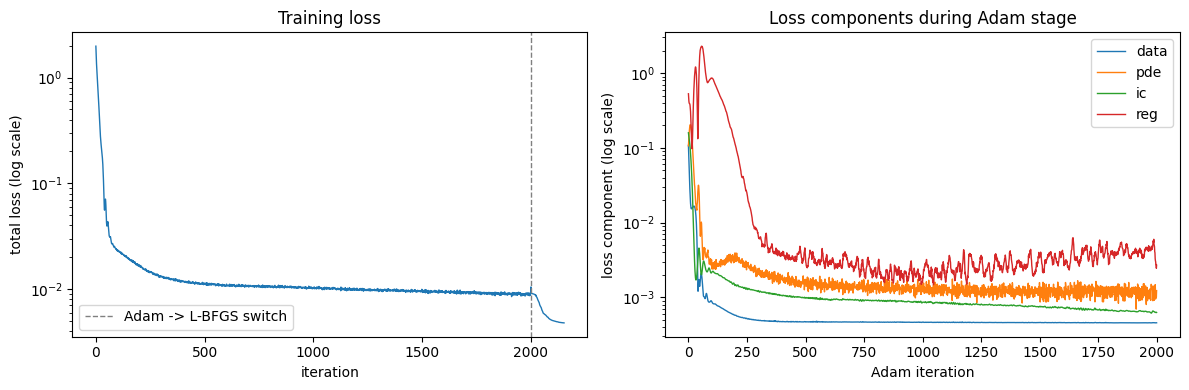

In [30]:
# ---- Loss curves --------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(history["total"], lw=1)
ax[0].axvline(N_ADAM_ITERS, color="gray", ls="--", lw=1, label="Adam -> L-BFGS switch")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("total loss (log scale)")
ax[0].set_title("Training loss"); ax[0].legend()

for k in ("data", "pde", "ic", "reg"):
    ax[1].semilogy(history[k][:N_ADAM_ITERS], lw=1, label=k)
ax[1].set_xlabel("Adam iteration"); ax[1].set_ylabel("loss component (log scale)")
ax[1].set_title("Loss components during Adam stage"); ax[1].legend()
plt.tight_layout(); plt.show()


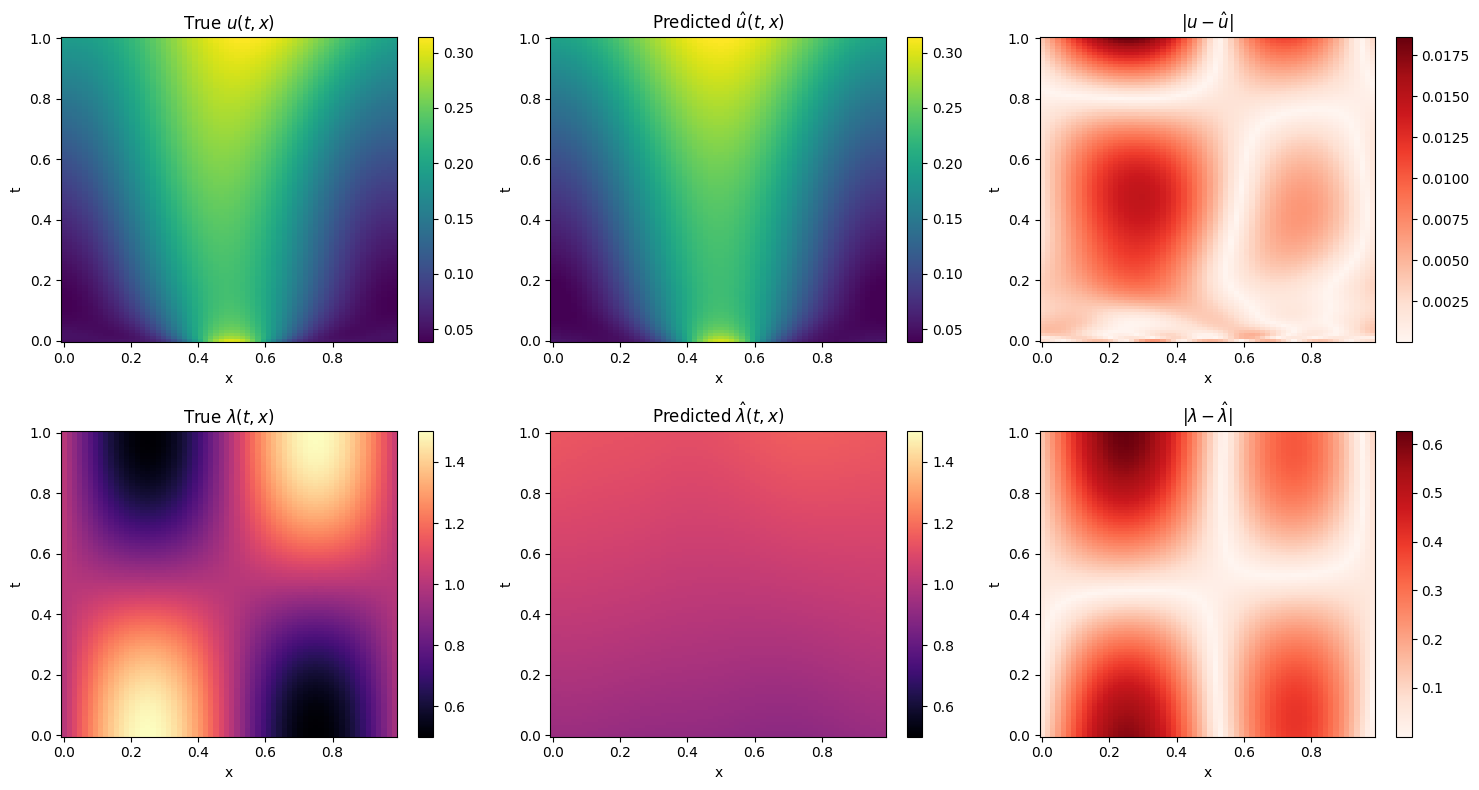

Summary:
  relative L2 error (u)      = 0.0327
  relative L2 error (lambda) = 0.2486


In [31]:
# ---- True vs. predicted u(t,x) and lambda(t,x) --------------------------------
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for row, (true_f, pred_f, name, cmap) in enumerate([
        (U_true, U_pred, "u", "viridis"),
        (Lam_true_grid, Lam_pred, r"\lambda", "magma")]):
    vmin, vmax = true_f.min(), true_f.max()
    im0 = axes[row, 0].pcolormesh(Xm, Tm, true_f, shading="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    axes[row, 0].set_title(f"True ${name}(t,x)$"); fig.colorbar(im0, ax=axes[row, 0])
    im1 = axes[row, 1].pcolormesh(Xm, Tm, pred_f, shading="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    axes[row, 1].set_title(f"Predicted $\\hat{{{name}}}(t,x)$"); fig.colorbar(im1, ax=axes[row, 1])
    err = np.abs(true_f - pred_f)
    im2 = axes[row, 2].pcolormesh(Xm, Tm, err, shading="auto", cmap="Reds")
    axes[row, 2].set_title(f"$|{name} - \\hat{{{name}}}|$"); fig.colorbar(im2, ax=axes[row, 2])
    for c in range(3):
        axes[row, c].set_xlabel("x"); axes[row, c].set_ylabel("t")

plt.tight_layout(); plt.show()

print("Summary:")
print("  relative L2 error (u)      = %.4f" % rel_L2_u)
print("  relative L2 error (lambda) = %.4f" % rel_L2_lambda)


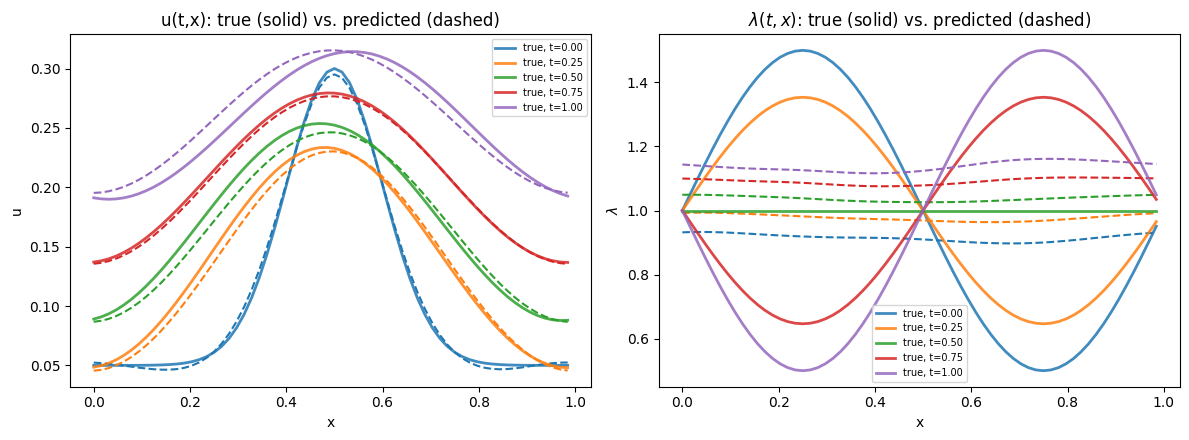

In [32]:
# ---- Slices at fixed times: true vs. predicted u and lambda --------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for t_slice in [0.0, 0.25, 0.5, 0.75, 1.0]:
    it_s = np.argmin(np.abs(t_grid - t_slice))
    axes[0].plot(x_grid, U_true[it_s], "-", lw=2, alpha=0.85, label=f"true, t={t_grid[it_s]:.2f}")
    axes[0].plot(x_grid, U_pred[it_s], "--", lw=1.5, color=axes[0].lines[-1].get_color())
    axes[1].plot(x_grid, Lam_true_grid[it_s], "-", lw=2, alpha=0.85, label=f"true, t={t_grid[it_s]:.2f}")
    axes[1].plot(x_grid, Lam_pred[it_s], "--", lw=1.5, color=axes[1].lines[-1].get_color())

axes[0].set_xlabel("x"); axes[0].set_ylabel("u"); axes[0].set_title("u(t,x): true (solid) vs. predicted (dashed)")
axes[0].legend(fontsize=7)
axes[1].set_xlabel("x"); axes[1].set_ylabel(r"$\lambda$"); axes[1].set_title(r"$\lambda(t,x)$: true (solid) vs. predicted (dashed)")
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()


### 5.11 Comparison experiment: mollifier vs. pure autodiff

We now quantify the claims of §1.5 and §2.5 directly:

1. A **microbenchmark** isolating the cost (wall-clock time and Python-level peak
   memory, via `tracemalloc`) of computing $\hat u_{xxxx}$ alone — one call via
   the mollifier layer, one via 4 nested `torch.autograd.grad` calls — at the
   same collocation batch size and network size.
2. A **short, fully matched comparative training run**: two freshly initialized
   models (identical architecture, identical seed, identical hyperparameters),
   one trained with the mollifier residual and one with the pure-autodiff
   residual, for the same (modest) number of Adam iterations, so that final
   accuracy and average per-iteration cost can be compared directly.

If a GPU is available, `torch.cuda.max_memory_allocated()` is also reported,
which is a more standard proxy for the "GPU memory" comparison requested in the
task; on CPU-only machines `tracemalloc` gives an analogous (Python-object-level)
signal.


In [33]:
# ---- 1) Microbenchmark: cost of computing u_xxxx alone -----------------------
N_BENCH_REPEATS = 20
t_bench, x_bench = sample_collocation(np.random.default_rng(7), n=N_r)

def bench_mollifier():
    tracemalloc.start()
    t0 = time.perf_counter()
    for _ in range(N_BENCH_REPEATS):
        u_net.zero_grad()
        out = moll4(u_net, t_bench, x_bench)
        out.sum().backward()
    elapsed = (time.perf_counter() - t0) / N_BENCH_REPEATS
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return elapsed, peak

def bench_autodiff():
    tracemalloc.start()
    t0 = time.perf_counter()
    for _ in range(N_BENCH_REPEATS):
        u_net.zero_grad()
        out = autodiff_4th_derivative(u_net, t_bench, x_bench)
        out.sum().backward()
    elapsed = (time.perf_counter() - t0) / N_BENCH_REPEATS
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return elapsed, peak

t_moll, mem_moll = bench_mollifier()
t_auto, mem_auto = bench_autodiff()

print("Cost of computing u_xxxx (forward + backward), averaged over %d repeats, N=%d points:" % (N_BENCH_REPEATS, N_r))
print("  Mollifier layer : %.4f s/iter, peak Python memory ~ %.2f MB" % (t_moll, mem_moll / 1e6))
print("  Pure autodiff   : %.4f s/iter, peak Python memory ~ %.2f MB" % (t_auto, mem_auto / 1e6))
if torch.cuda.is_available():
    print("  (CUDA detected but benchmark run on CPU tensors above; "
          "re-run with .to('cuda') tensors/models to also see torch.cuda.max_memory_allocated().)")


Cost of computing u_xxxx (forward + backward), averaged over 20 repeats, N=500 points:
  Mollifier layer : 0.0405 s/iter, peak Python memory ~ 0.01 MB
  Pure autodiff   : 0.0668 s/iter, peak Python memory ~ 0.01 MB
  (CUDA detected but benchmark run on CPU tensors above; re-run with .to('cuda') tensors/models to also see torch.cuda.max_memory_allocated().)


In [34]:
# ---- 2) Matched short comparative training run --------------------------------
def make_fresh_models(seed):
    torch.manual_seed(seed)
    u = UNet(L=L, hidden=64, depth=4)
    lam = LambdaNet(L=L, hidden=32, depth=3)
    return u, lam

def train_short(u_xxxx_mode, n_iters=800, seed=SEED):
    '''Train a fresh model pair for n_iters Adam iterations, using either the
    mollifier layer ("mollifier") or nested autodiff ("autodiff") for u_xxxx.
    Returns the trained models, per-iteration timings, and loss history.'''
    u_m, lam_m = make_fresh_models(seed)
    moll_local = MollifierDeriv1D(eps=0.02, order=4, L=L, n_per_eps=4, M=6.0)
    opt = torch.optim.Adam(list(u_m.parameters()) + list(lam_m.parameters()), lr=1e-3)
    rng_local = np.random.default_rng(seed + 100)

    def residual_fn(t_c, x_c):
        t_c = t_c.clone().requires_grad_(True)
        x_c = x_c.clone().requires_grad_(True)
        u = u_m(t_c, x_c)
        ones = torch.ones_like(u)
        u_t = torch.autograd.grad(u, t_c, grad_outputs=ones, create_graph=True)[0]
        u_x = torch.autograd.grad(u, x_c, grad_outputs=ones, create_graph=True)[0]
        u_xx = torch.autograd.grad(u_x, x_c, grad_outputs=ones, create_graph=True)[0]
        if u_xxxx_mode == "mollifier":
            u_xxxx = moll_local(u_m, t_c, x_c)
        else:
            u_xxxx = autodiff_4th_derivative(u_m, t_c, x_c)
        lam = lam_m(t_c, x_c)
        r = u_t + D4 * u_xxxx - D2 * u_xx - lam * u * (1.0 - u)
        return r

    iter_times = []
    losses = []
    for it in range(n_iters):
        t_c, x_c = sample_collocation(rng_local)
        t0 = time.perf_counter()
        opt.zero_grad()
        u_pred_obs = u_m(t_obs_t, x_obs_t)
        mse_data = torch.mean((u_pred_obs - u_obs_t) ** 2)
        r = residual_fn(t_c, x_c)
        mse_pde = torch.mean(r ** 2)
        u_pred_ic = u_m(t_ic_t, x_ic_t)
        mse_ic = torch.mean((u_pred_ic - u_ic_t) ** 2)
        loss = W_DATA * mse_data + W_PDE * mse_pde + W_IC * mse_ic
        loss.backward()
        opt.step()
        iter_times.append(time.perf_counter() - t0)
        losses.append(loss.item())

    return u_m, lam_m, np.array(iter_times), losses

N_COMPARE_ITERS = 400
print("Training comparison model (mollifier)...")
u_moll_cmp, lam_moll_cmp, times_moll, losses_moll = train_short("mollifier", n_iters=N_COMPARE_ITERS)
print("Training comparison model (pure autodiff)...")
u_auto_cmp, lam_auto_cmp, times_auto, losses_auto = train_short("autodiff", n_iters=N_COMPARE_ITERS)

with torch.no_grad():
    U_pred_moll_cmp = u_moll_cmp(Tm_flat, Xm_flat).numpy().reshape(Tm.shape)
    U_pred_auto_cmp = u_auto_cmp(Tm_flat, Xm_flat).numpy().reshape(Tm.shape)
    Lam_pred_moll_cmp = lam_moll_cmp(Tm_flat, Xm_flat).numpy().reshape(Tm.shape)
    Lam_pred_auto_cmp = lam_auto_cmp(Tm_flat, Xm_flat).numpy().reshape(Tm.shape)

def rel_l2(a, b):
    return np.linalg.norm(a - b) / np.linalg.norm(b)

print("\n=== Comparison after %d matched Adam iterations ===" % N_COMPARE_ITERS)
print(f"{'method':<12}{'avg s/iter':>12}{'rel L2 u':>12}{'rel L2 lambda':>16}")
print(f"{'mollifier':<12}{times_moll.mean():>12.4f}{rel_l2(U_pred_moll_cmp, U_true):>12.4f}"
      f"{rel_l2(Lam_pred_moll_cmp, Lam_true_grid):>16.4f}")
print(f"{'autodiff':<12}{times_auto.mean():>12.4f}{rel_l2(U_pred_auto_cmp, U_true):>12.4f}"
      f"{rel_l2(Lam_pred_auto_cmp, Lam_true_grid):>16.4f}")


Training comparison model (mollifier)...
Training comparison model (pure autodiff)...

=== Comparison after 400 matched Adam iterations ===
method        avg s/iter    rel L2 u   rel L2 lambda
mollifier         0.0615      0.0454          0.2413
autodiff          0.0727      0.0455          0.2414


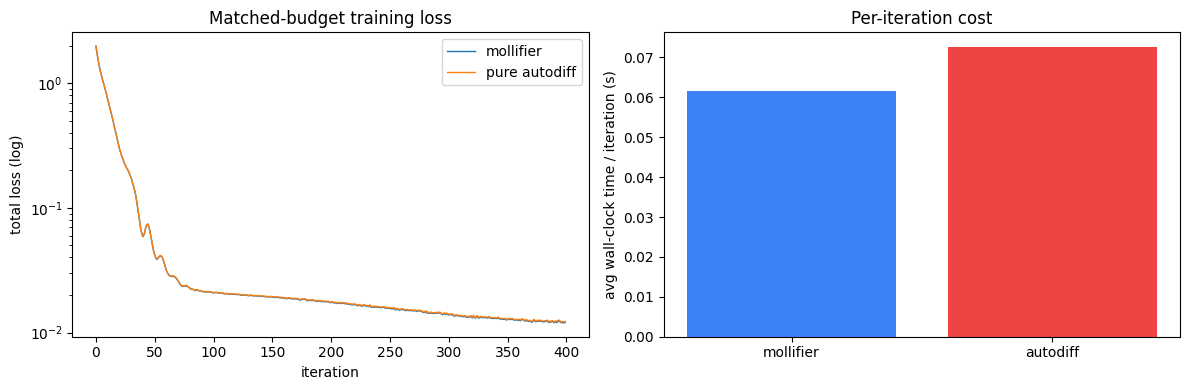

In [35]:
# ---- Visualize the comparison ---------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogy(losses_moll, label="mollifier", lw=1)
axes[0].semilogy(losses_auto, label="pure autodiff", lw=1)
axes[0].set_xlabel("iteration"); axes[0].set_ylabel("total loss (log)")
axes[0].set_title("Matched-budget training loss"); axes[0].legend()

axes[1].bar(["mollifier", "autodiff"], [times_moll.mean(), times_auto.mean()],
            color=["#3b82f6", "#ef4444"])
axes[1].set_ylabel("avg wall-clock time / iteration (s)")
axes[1].set_title("Per-iteration cost")
plt.tight_layout(); plt.show()


## 6. Conclusions and Discussion

### 6.1 Summary

We formulated the inverse problem of recovering a spatio-temporal reaction rate
$\lambda(t,x)$ in a fourth-order ("bi-harmonic") reaction–diffusion model of
epidemic spread from sparse, noisy observations of $u(t,x)$, and solved it with
a Physics-Informed Neural Network. The key numerical contribution was the
**mollifier layer**: instead of computing the required 4th-order spatial
derivative $u_{xxxx}$ by four nested `torch.autograd.grad` calls (unstable and
memory-hungry, §1.5), we approximated it by convolving stencil evaluations of
the network against the **analytically known** 4th derivative of a Gaussian
mollifier (§2), implemented as a fixed-weight `conv1d` layer that remains fully
differentiable with respect to the network parameters. The notebook:

- derived the mollifier approximation from first principles (Friedrichs
  mollification theorem, commutation of differentiation and convolution);
- built and validated Gaussian and bump-function kernels and their derivatives,
  in both 1D and 2D;
- generated a synthetic ground truth with a spectral forward solver and sparse
  noisy observations;
- trained a mollifier-based PINN to jointly reconstruct $u(t,x)$ and
  $\lambda(t,x)$, reporting relative $L^2$ errors, residual norms, and a direct
  correlation check of the mollifier-estimated derivative against a
  finite-difference reference;
- benchmarked the mollifier layer against pure recursive autodiff, both in
  isolation (cost of computing $u_{xxxx}$ alone) and in a matched end-to-end
  training comparison.

### 6.2 Limitations

- **Kernel truncation error.** The Gaussian kernel is truncated at $M\epsilon$
  (here $M=6$, as verified empirically in §5.3 — the naive $k{=}0$ estimate
  $M=4$ turned out to be insufficient for the $k{=}4$ derivative kernel, whose
  tail is polynomially reweighted by $He_4$); this introduces a small but
  non-zero bias, and interacts with the stencil spacing $h$ — if $h$ is not
  sufficiently smaller than $\epsilon$, the discrete Riemann-sum approximation
  of the convolution integral itself becomes an additional error source on top
  of the mollifier bias.
- **Choice of $\epsilon$.** As discussed in §2.4, $\epsilon$ trades bias against
  noise sensitivity; we fixed it by a simple sanity check against a known
  analytic function (§5.3), but a fully principled choice would treat $\epsilon$
  as a regularization hyperparameter to be selected e.g. by an L-curve /
  discrepancy-principle argument, or made spatially adaptive.
- **Computational cost of the convolution.** The mollifier layer trades
  *autodiff graph depth* for *evaluation breadth*: each collocation point now
  requires $2K{+}1$ network evaluations rather than one, which is cheap for
  small MLPs but would need to be weighed carefully for much larger
  architectures or 3D+time problems.
- **Simplified geometry.** The main experiment uses a 1D periodic spatial
  domain for computational tractability; the 2D kernel utilities were validated
  in isolation but not embedded in a full 2D PINN training loop here.

### 6.3 Extensions

- **Higher dimensions.** The mollifier layer generalizes directly to 2D/3D via
  separable (or non-separable, for anisotropic kernels) tensor-product
  convolutions (`conv2d`/`conv3d`), at the cost of a stencil that grows
  combinatorially with dimension — a cost that could be mitigated with sparse
  or low-rank stencils.
- **Learned mollifiers.** Rather than fixing $\varphi_\epsilon$ a priori, one
  could parameterize the kernel (e.g. a small MLP or a mixture of Gaussians
  with learnable widths) and learn it jointly with $\theta,\phi$, subject to the
  unit-mass and vanishing-moment constraints that preserve the consistency
  result of §2.3 — trading some interpretability for adaptivity.
- **Bayesian / uncertainty-quantified inversion.** The regularized least-squares
  functional $\mathcal J(\lambda)$ of §1.3 is the negative log-posterior of a
  Bayesian inverse problem with Gaussian likelihood and a Gaussian-process-like
  (or deep, e.g. Bayesian-neural-network) prior on $\lambda$. Replacing
  point-estimate training with, e.g., Hamiltonian Monte Carlo, deep ensembles,
  or variational inference over $\phi$ would turn the current $\hat\lambda_\phi$
  point estimate into a full posterior, giving calibrated uncertainty bands on
  the reconstructed reaction rate — directly useful for downstream
  epidemiological decision-making.
